# Chapitre 7 - Cours 5 : pourquoi sharder ? Avantages, inconvénients et multi-location

Les cours 1 à 4 ont répondu à la question « comment sharder ? ». Ce dernier cours prend
du recul et pose deux questions que la 2e édition du livre traite en ouverture du
chapitre : **faut-il sharder**, et à quel prix ? Et le sharding peut-il servir à autre
chose qu'à passer à l'échelle, en particulier à **isoler les clients** d'un logiciel
multi-locataire (SaaS) ? Il couvre les sections *Pros and Cons of Sharding* et
*Sharding for Multitenancy*.

**Plan.**

1. Quand une seule machine suffit : ordres de grandeur.
2. Ce que le sharding apporte : des écritures qui passent à l'échelle.
3. Le prix : clé de partitionnement et transactions multi-shards.
4. Sharder à l'intérieur d'une machine : un processus par cœur.
5. Multi-location : un locataire, un shard ?
6. Isolation : voisin bruyant, permissions et architecture cellulaire.
7. Sauvegarde, effacement, résidence et migrations progressives.
8. Les difficultés : locataires qui grandissent, géants et requêtes transverses.

In [1]:
import sqlite3
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia import partitioning_tenants as T
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Quand une seule machine suffit (section *Pros and Cons of Sharding*)

**Le problème.** Le sharding est la principale technique de **mise à l'échelle
horizontale** (*scale-out*) : au lieu d'acheter une machine plus grosse, on répartit les
données et les écritures sur plusieurs machines plus modestes, chacune responsable d'une
part à peu près égale. Mais le livre insiste sur un point souvent oublié : c'est une
solution **lourde**, qui ne se justifie qu'à grande échelle. La réplication, elle, est
utile à toute taille (tolérance aux pannes, lectures locales) ; le sharding ajoute de la
complexité dont on se passe volontiers tant qu'une seule machine tient la charge.

Or « une seule machine » est une quantité qui a beaucoup grandi. Un serveur haut de gamme
actuel compte des centaines de cœurs, plusieurs téraoctets de mémoire et des dizaines,
voire une centaine de téraoctets de SSD NVMe. Comparons ces limites à quelques charges
typiques (ordres de grandeur indicatifs, à remplacer par vos chiffres), puis calculons
combien d'années une charge qui croît de $g$ % par an met à dépasser la machine :
$t = \ln(C / V_0) / \ln(1 + g)$.

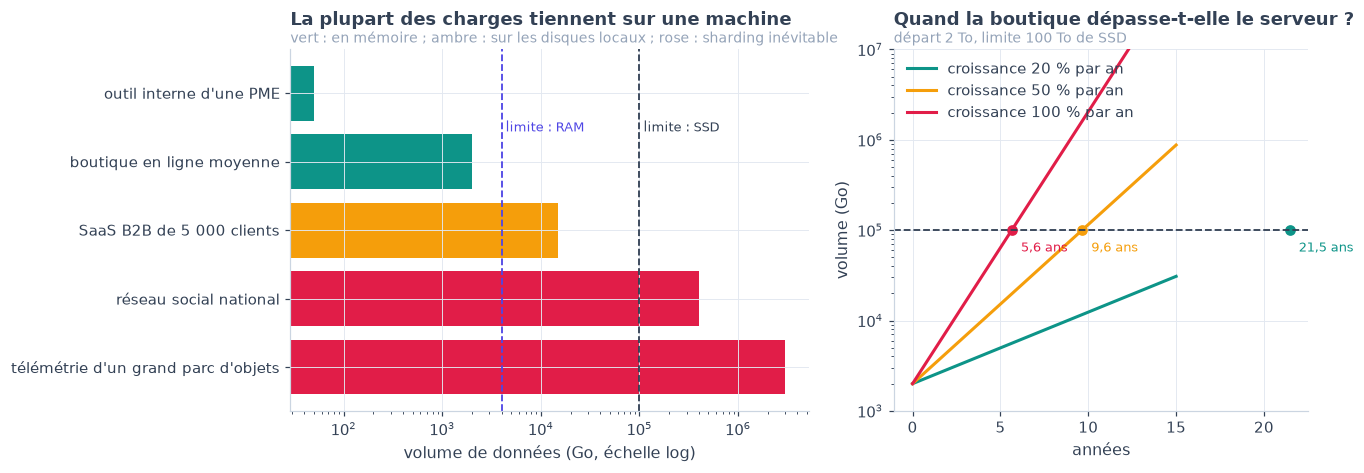

In [2]:
charges = pd.DataFrame({
    "charge": ["outil interne d'une PME", "boutique en ligne moyenne", "SaaS B2B de 5 000 clients",
               "réseau social national", "télémétrie d'un grand parc d'objets"],
    "donnees_Go": [50, 2_000, 15_000, 400_000, 3_000_000],
})
LIM_RAM, LIM_DISQUE = 4_000, 100_000          # Go : mémoire et SSD d'un gros serveur

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
cols = [TEAL if v < LIM_RAM else (AMBER if v < LIM_DISQUE else ROSE) for v in charges.donnees_Go]
ax1.barh(charges.charge, charges.donnees_Go, color=cols)
ax1.set_xscale("log")
ax1.axvline(LIM_RAM, color=INDIGO, ls="--", lw=1.2)
ax1.axvline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax1.text(LIM_RAM * 1.1, 0.5, "limite : RAM", color=INDIGO, fontsize=8.5, va="center")
ax1.text(LIM_DISQUE * 1.1, 0.5, "limite : SSD", color=SLATE, fontsize=8.5, va="center")
ax1.invert_yaxis()
ax1.set_xlabel("volume de données (Go, échelle log)")
ax1.set_title("La plupart des charges tiennent sur une machine")
subtitle(ax1, "vert : en mémoire ; ambre : sur les disques locaux ; rose : sharding inévitable")

V0 = 2_000
for g, c in [(0.2, TEAL), (0.5, AMBER), (1.0, ROSE)]:
    years = np.arange(0, 16)
    ax2.plot(years, V0 * (1 + g) ** years, color=c, label=f"croissance {g:.0%} par an".replace("%", " %"))
    t_cross = np.log(LIM_DISQUE / V0) / np.log(1 + g)
    ax2.plot([t_cross], [LIM_DISQUE], "o", color=c)
    ax2.annotate(f"{t_cross:.1f} ans".replace(".", ","), (t_cross, LIM_DISQUE), (6, -14),
                 textcoords="offset points", fontsize=8.5, color=c)
ax2.axhline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax2.set_yscale("log")
ax2.set_ylim(1e3, 1e7)
ax2.set_xlabel("années")
ax2.set_ylabel("volume (Go)")
ax2.set_title("Quand la boutique dépasse-t-elle le serveur ?")
subtitle(ax2, "départ 2 To, limite 100 To de SSD")
ax2.legend(loc="upper left")
finish(fig)
plt.show()

Avec 2 To aujourd'hui, une boutique qui croît de 20 % par an dispose de plus de vingt
ans de marge ; même à 50 % par an, il lui reste presque une décennie. Le livre en tire
une recommandation nette : tant que le volume et le **débit d'écriture** tiennent sur un
nœud, mieux vaut rester sur une base à un seul shard (répliquée pour la tolérance aux
pannes) et garder la simplicité. Ce raisonnement est volontairement optimiste : il ne
tient compte ni du débit d'écriture (souvent la vraie limite, section suivante), ni du
temps de reconstruction d'un nœud de 100 To après une panne, qui peut lui aussi pousser à
découper plus tôt.

> **À retenir.** Le sharding se justifie quand les données ou les écritures dépassent
> ce qu'un nœud peut porter. Une machine actuelle porte beaucoup : vérifiez les ordres de
> grandeur avant de payer la complexité du sharding.

## 2. Ce que le sharding apporte : des écritures qui passent à l'échelle (section *Pros and Cons of Sharding*)

Si c'est le débit de **lecture** qui sature, le chapitre 6 offre une
réponse plus simple : ajouter des suiveurs qui servent les lectures. Mais chaque suiveur
doit rejouer **toutes** les écritures : la réplication multiplie la capacité de lecture,
pas celle d'écriture. Le sharding, lui, découpe aussi les écritures : avec $n$ shards
équilibrés, chaque nœud n'en reçoit que $1/n$.

Modélisons un nœud capable de 20 000 opérations par seconde et une charge composée à 90 %
de lectures. Avec $r$ suiveurs, chaque nœud consacre une part de sa capacité à appliquer
le flux d'écritures complet ; avec $n$ shards (chacun répliqué, mais servant sa part),
les écritures se partagent.

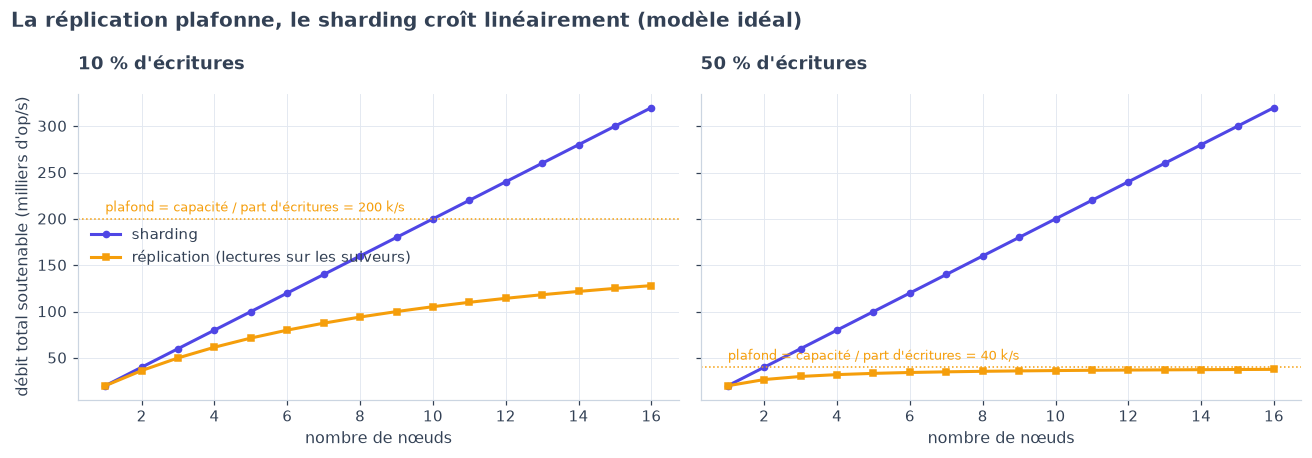

In [3]:
CAP = 20_000                       # opérations/s par nœud
nodes = np.arange(1, 17)

def capacity_replicas(n, write_frac):
    # tous les nœuds appliquent toutes les écritures ; les lectures se répartissent.
    # débit total X : écritures w = f X appliquées n fois, lectures (1 - f) X réparties
    # contrainte par nœud : f X + (1 - f) X / n <= CAP
    return CAP / (write_frac + (1 - write_frac) / n)

def capacity_shards(n, write_frac):
    return CAP * n                  # chaque opération ne touche qu'un shard

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, wf in zip(axes, [0.1, 0.5]):
    xr = capacity_replicas(nodes, wf)
    xs = capacity_shards(nodes, wf)
    ax.plot(nodes, xs / 1e3, color=INDIGO, marker="o", ms=4, label="sharding")
    ax.plot(nodes, xr / 1e3, color=AMBER, marker="s", ms=4, label="réplication (lectures sur les suiveurs)")
    ax.axhline(CAP / wf / 1e3, color=AMBER, ls=":", lw=1)
    ax.text(1, CAP / wf / 1e3 + 8, f"plafond = capacité / part d'écritures = {CAP / wf / 1e3:.0f} k/s",
            ha="left", color=AMBER, fontsize=8.5)
    ax.set_xlabel("nombre de nœuds")
    ax.set_title(f"{wf:.0%} d'écritures".replace("%", " %"))
axes[0].set_ylabel("débit total soutenable (milliers d'op/s)")
axes[0].legend(loc="center left")
finish(fig, "La réplication plafonne, le sharding croît linéairement (modèle idéal)")
plt.show()

Avec 10 % d'écritures, la réplication plafonne à dix fois la capacité d'un nœud ; avec
50 %, au double. Le sharding croît linéairement, **dans le cas idéal** où les shards
sont équilibrés et où chaque opération ne touche qu'un shard. Les cours 2 et 3 ont montré
ce que coûte le déséquilibre ; la section suivante chiffre la seconde hypothèse.

> **À retenir.** Réplication et sharding se complètent : la première multiplie les
> lectures et apporte la tolérance aux pannes, le second est le seul des deux qui
> multiplie la capacité d'**écriture** et de **stockage**.

## 3. Le prix : clé de partitionnement et transactions multi-shards (section *Pros and Cons of Sharding*)

Sharder impose de choisir une **clé de partitionnement** : tous les enregistrements de
même clé vont dans le même shard. Accéder à un enregistrement dont on connaît la clé est
rapide ; tout le reste (recherche par un autre attribut, jointure, mise à jour de
plusieurs enregistrements) risque de toucher plusieurs shards. Et ce choix est **difficile
à changer** une fois les données en place.

Le cas le plus coûteux est la transaction qui écrit dans plusieurs shards : elle exige
une **transaction distribuée** (validation en deux phases, chapitre 8),
bien plus lente qu'une transaction locale. Si une transaction touche $k$ enregistrements
placés au hasard parmi $n$ shards, la probabilité qu'ils tombent tous dans le même shard
vaut $(1/n)^{k-1}$ : elle s'effondre dès $k = 2$.

In [4]:
ks = np.arange(1, 7)
rows = []
for n in [2, 4, 16, 64]:
    rows.append([T.single_shard_probability(n, k) for k in ks])
tab = pd.DataFrame(rows, index=[f"{n} shards" for n in [2, 4, 16, 64]],
                   columns=[f"k = {k}" for k in ks])
print("Probabilité qu'une transaction sur k enregistrements aléatoires reste sur un seul shard :")
tab.map(lambda v: f"{v:.1%}".replace(".", ","))

Probabilité qu'une transaction sur k enregistrements aléatoires reste sur un seul shard :


,k = 1,k = 2,k = 3,k = 4,k = 5,k = 6
2 shards,"100,0%","50,0%","25,0%","12,5%","6,2%","3,1%"
4 shards,"100,0%","25,0%","6,2%","1,6%","0,4%","0,1%"
16 shards,"100,0%","6,2%","0,4%","0,0%","0,0%","0,0%"
64 shards,"100,0%","1,6%","0,0%","0,0%","0,0%","0,0%"


Avec 16 shards, une transaction qui touche deux enregistrements quelconques n'a qu'une
chance sur seize d'être locale. Tout l'art du choix de la clé consiste à faire que les
enregistrements écrits ensemble partagent la même clé : par exemple, toutes les lignes
d'une commande et le compte du client sous la clé « client ». Chiffrons l'enjeu avec un
petit modèle de latence :

- transaction **locale** : exécution (0,5 ms) puis écriture durable du journal (`fsync`,
  environ 1 ms) ;
- transaction **distribuée** : exécution, aller-retour vers les participants (0,5 ms),
  phase de préparation (aller-retour + `fsync` sur chaque participant, on attend le plus
  lent), journalisation de la décision par le coordinateur (`fsync`), phase de validation
  (aller-retour).

Les durées de `fsync` sont tirées selon une loi log-normale (queue lourde), ce qui
pénalise la transaction distribuée deux fois : elle cumule les étapes **et** attend le
participant le plus lent.

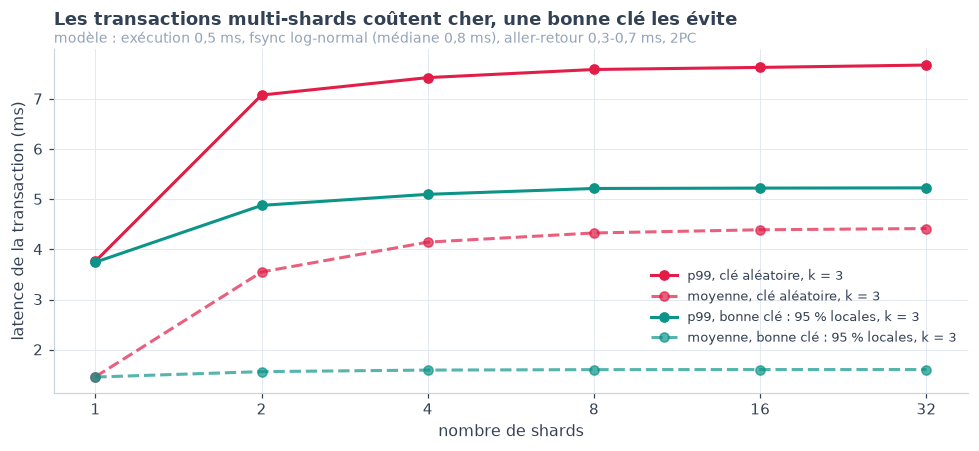

multi                       \
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3   
shards                                                          
1                                   0.00                 0.00   
2                                   0.04                 0.75   
4                                   0.05                 0.94   
8                                   0.05                 0.98   
16                                  0.05                 1.00   
32                                  0.05                 1.00   

                                 moyenne                       \
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3   
shards                                                          
1                                   1.45                 1.46   
2                                   1.56                 3.55   
4                                   1.59                 4.15   
8                                   1.60                 4.33   
16                                  1.60                 4.39   
32                                  1.60                 4.42   

                                     p99                       
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3  
shards                                                         
1                                   3.75                 3.76  
2                                   4.88                 7.08  
4                                   5.10                 7.43  
8                                   5.21                 7.59  
16                                  5.22                 7.63  
32                                  5.23                 7.68

In [5]:
def txn_latency(n_shards, k, n_txn=40_000, local_frac=None, seed=0):
    """Latence (ms) de transactions sur k enregistrements ; local_frac : part forcée sur un seul shard."""
    r = np.random.default_rng(seed)
    shards = r.integers(0, n_shards, size=(n_txn, k))
    if local_frac is not None:
        loc = r.random(n_txn) < local_frac
        shards[loc] = shards[loc, :1]
    n_part = np.array([len(set(row)) for row in shards])
    fsync = lambda size: r.lognormal(np.log(0.8), 0.6, size)
    rtt = lambda size: r.uniform(0.3, 0.7, size)
    single = 0.5 + fsync(n_txn)
    prepare = rtt(n_txn) + np.array([fsync(m).max() for m in n_part])
    distributed = 0.5 + rtt(n_txn) + prepare + fsync(n_txn) + rtt(n_txn)
    return np.where(n_part == 1, single, distributed), n_part

res = []
for n in [1, 2, 4, 8, 16, 32]:
    for label, kw in [("clé aléatoire, k = 3", dict(k=3)),
                      ("bonne clé : 95 % locales, k = 3", dict(k=3, local_frac=0.95))]:
        lat, npart = txn_latency(n, **kw)
        res.append({"shards": n, "scénario": label, "moyenne": lat.mean(), "p99": np.percentile(lat, 99),
                    "multi": np.mean(npart > 1)})
res = pd.DataFrame(res)

fig, ax = plt.subplots(figsize=(9, 4.2))
for (label, g), c in zip(res.groupby("scénario", sort=False), [ROSE, TEAL]):
    ax.plot(g.shards, g.p99, color=c, marker="o", label=f"p99, {label}")
    ax.plot(g.shards, g.moyenne, color=c, marker="o", ls="--", alpha=0.7, label=f"moyenne, {label}")
ax.set_xscale("log", base=2)
ax.set_xticks([1, 2, 4, 8, 16, 32]); ax.set_xticklabels([1, 2, 4, 8, 16, 32])
ax.set_xlabel("nombre de shards")
ax.set_ylabel("latence de la transaction (ms)")
ax.set_title("Les transactions multi-shards coûtent cher, une bonne clé les évite")
subtitle(ax, "modèle : exécution 0,5 ms, fsync log-normal (médiane 0,8 ms), aller-retour 0,3-0,7 ms, 2PC")
ax.legend(fontsize=8.5, loc="center right", bbox_to_anchor=(1.0, 0.25))
plt.tight_layout(); plt.show()
res.pivot(index="shards", columns="scénario", values=["multi", "moyenne", "p99"]).round(2)

Le tableau confirme l'intuition : avec une clé aléatoire, la part de transactions
multi-shards passe de 75 % (2 shards) à presque 100 %, et la latence moyenne est
multipliée par deux à trois par rapport à une base unique ; le p99, qui attend le
participant le plus lent, se dégrade encore à mesure que la transaction touche plus de
participants. Avec une clé qui rend 95 % des transactions locales, la moyenne reste
proche de celle d'un seul nœud. Ce modèle ignore en plus l'essentiel du coût réel : les
verrous tenus pendant les deux phases, qui réduisent le débit des enregistrements
chauds, et la fragilité face à la panne du coordinateur (chapitre 8).

Le même raisonnement vaut pour les requêtes : le sharding se marie bien avec les données
clé-valeur, beaucoup moins avec le relationnel où l'on cherche par index secondaire
(cours 4) et où l'on joint des enregistrements qui vivent sur des shards différents.

> **À retenir.** Le sharding se paie en accès multi-shards : recherches dispersées,
> jointures distantes et transactions distribuées. Le choix de la clé de
> partitionnement décide de la part de ces opérations ; il faut le faire tôt, car il est
> difficile à défaire.